# **Прикладные задачи МО на графах. 12.11.2025**

Библиотека для работы с графовыми нейронными сетями  
[PyG (PyTorch Geometric)](https://github.com/rusty1s/pytorch_geometric).
PyTorch Geometric  - это расширение к [PyTorch](https://pytorch.org/).

In [1]:
# Установка нужных пакетов
import os
import torch


!pip install -q torch-scatter -f https://data.pyg.org/whl/torch-2.4.0+cu121.html
!pip install -q torch-sparse -f https://data.pyg.org/whl/torch-2.4.0+cu121.html
!pip install -q torch-geometric

In [2]:
import matplotlib.pyplot as plt
import torch.nn.functional as F
from torch_geometric.nn import GATv2Conv
from torch.nn import Linear, Dropout
from torch_geometric.utils import degree

/usr/local/lib/python3.12/dist-packages/torch_geometric/__init__.py:4: UserWarning: An issue occurred while importing 'torch-scatter'. Disabling its usage. Stacktrace: Could not load this library: /usr/local/lib/python3.12/dist-packages/torch_scatter/_version_cuda.so
  import torch_geometric.typing
/usr/local/lib/python3.12/dist-packages/torch_geometric/__init__.py:4: UserWarning: An issue occurred while importing 'torch-sparse'. Disabling its usage. Stacktrace: Could not load this library: /usr/local/lib/python3.12/dist-packages/torch_sparse/_version_cuda.so
  import torch_geometric.typing


In [3]:
import networkx as nx
import numpy as np

## Graph Convolutional layer (GCN)

GCN в матричном виде можно записать
$$ H^{(l+1)} = \sigma ( \tilde{D}^{-1/2} \tilde{A} \tilde{D}^{-1/2} H^{(l)} W^{(l)}),$$

где $\tilde{A} = A +I$.

"Сообщения" от соседей могут иметь разный вклад в итоговый вектор признаков в том числе в зависимости от нормирования.

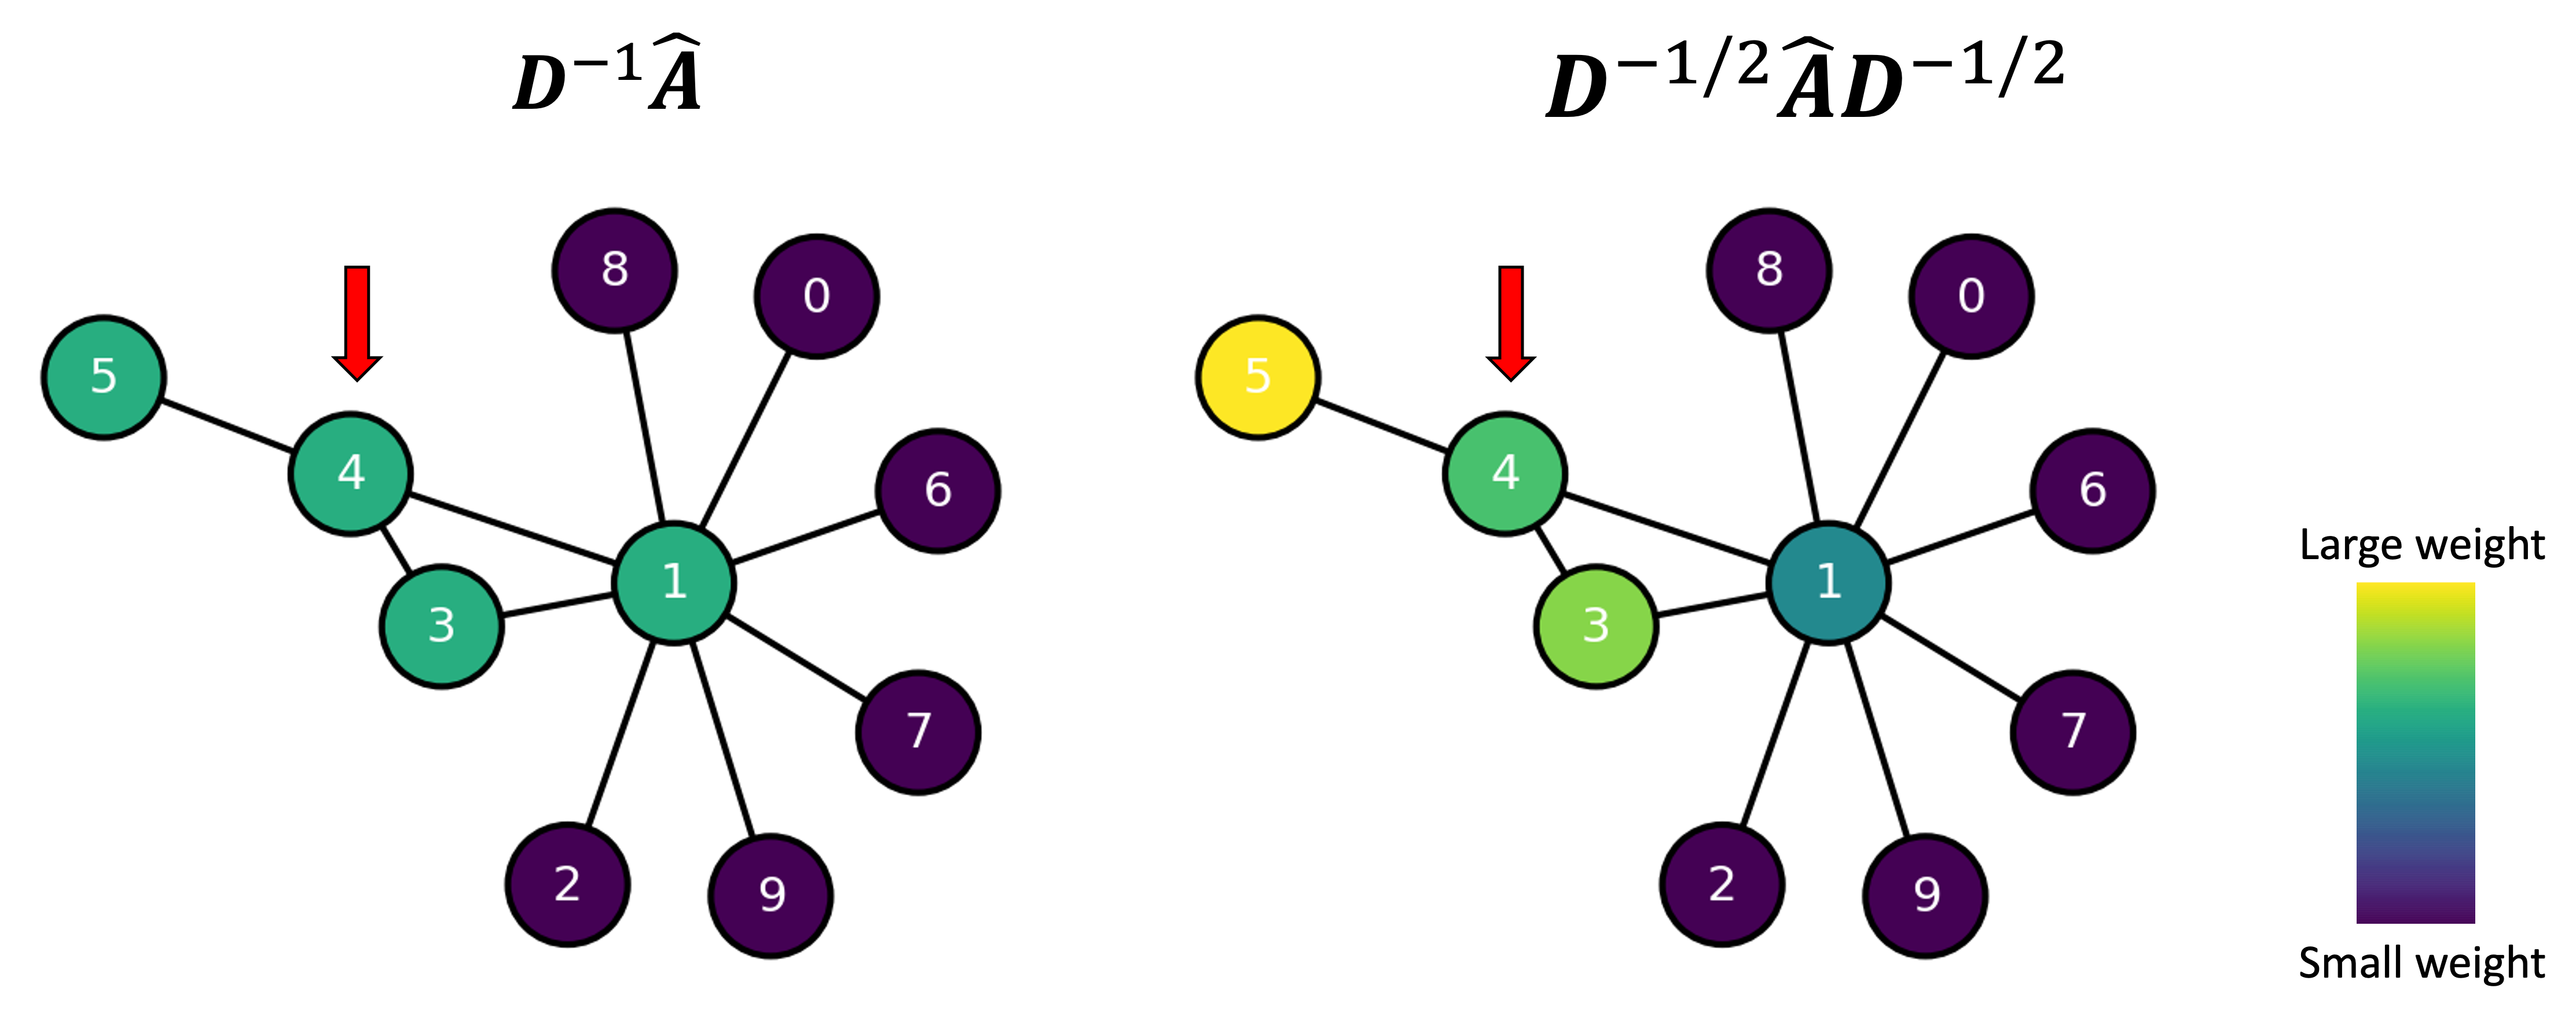

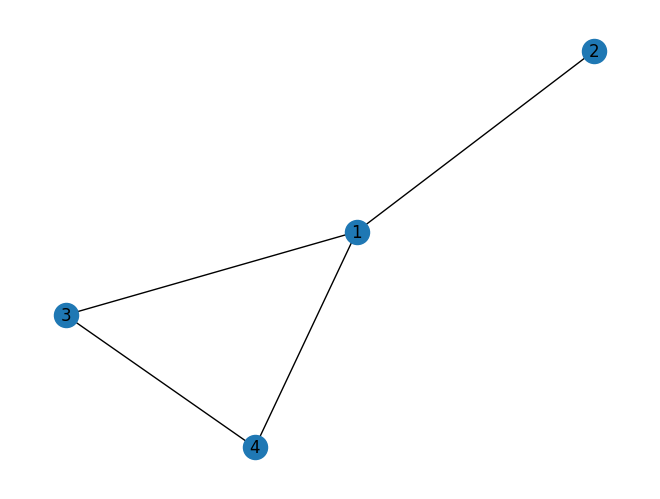

In [ ]:
# Граф
G = nx.Graph()
G.add_edges_from([(1, 2), (1, 3), (1, 4), (3, 4)])
nx.draw(G, with_labels = True)

In [ ]:
# Матрица смежности
A = nx.adjacency_matrix(G).toarray()

# Матрица смежности с учетом петель
A_tilde = A + np.identity(4)

In [ ]:
# Диагональная матрица степеней
G_node_degrees = [degree[1] for degree in G.degree()]
D = np.diag(G_node_degrees)
D

array([[3, 0, 0, 0],
       [0, 1, 0, 0],
       [0, 0, 2, 0],
       [0, 0, 0, 2]])

In [ ]:
# Диагональная матрица степеней (с учетом петель)
D_tilde = D + np.identity(4)
D_tilde

array([[4., 0., 0., 0.],
       [0., 2., 0., 0.],
       [0., 0., 3., 0.],
       [0., 0., 0., 3.]])

*   $\tilde{D}^{-1}\tilde{A} X W$ --- нормируем строки матрицы признаков $X$
*   $\tilde{A}\tilde{D}^{-1} X W$ --- нормируем столбцы матрицы признаков $X$



In [ ]:
print(np.linalg.inv(D_tilde) @ A_tilde)

[[0.25       0.25       0.25       0.25      ]
 [0.5        0.5        0.         0.        ]
 [0.33333333 0.         0.33333333 0.33333333]
 [0.33333333 0.         0.33333333 0.33333333]]


In [ ]:
print(A_tilde @ np.linalg.inv(D_tilde))

[[0.25       0.5        0.33333333 0.33333333]
 [0.25       0.5        0.         0.        ]
 [0.25       0.         0.33333333 0.33333333]
 [0.25       0.         0.33333333 0.33333333]]


* $\tilde{D}^{-1/2} \tilde{A} \tilde{D}^{-1/2}$ - симметрическая нормализация.



In [ ]:
print(np.linalg.inv(np.sqrt(D_tilde)) @ A_tilde @ np.linalg.inv(np.sqrt(D_tilde)))

[[0.25       0.35355339 0.28867513 0.28867513]
 [0.35355339 0.5        0.         0.        ]
 [0.28867513 0.         0.33333333 0.33333333]
 [0.28867513 0.         0.33333333 0.33333333]]


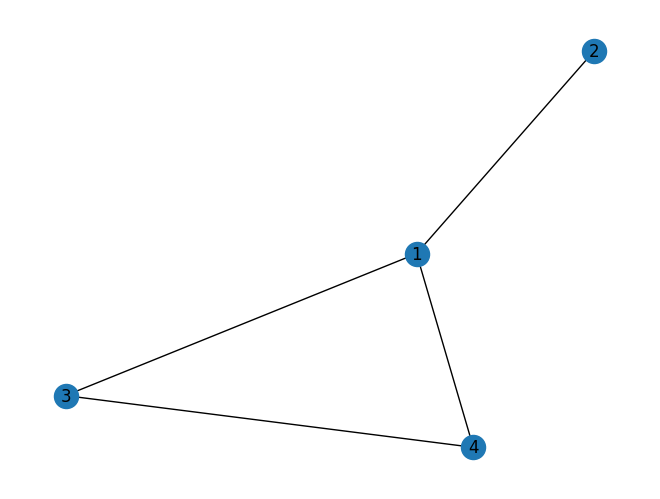

In [ ]:
nx.draw(G, with_labels = True)

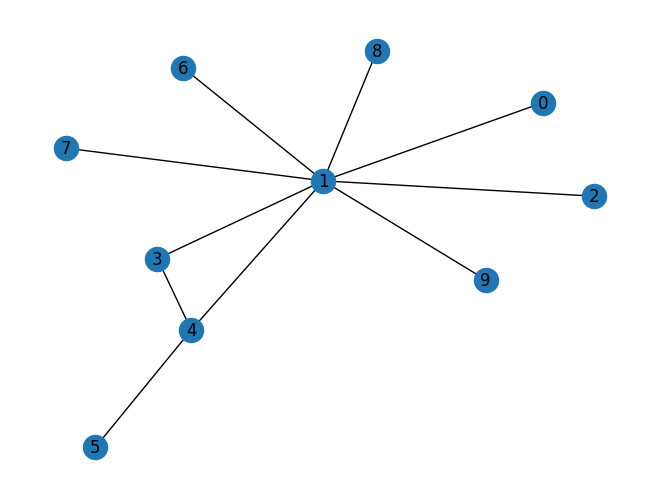

In [ ]:
# Еще один граф
G2 = nx.Graph()
G2.add_edges_from([(0, 1), (1, 2), (1, 3), (1, 4), (3, 4), (4, 5),
 (1, 6), (1, 7), (1, 8), (1, 9)])
nx.draw(G2,  with_labels = True)

In [ ]:
A2 = nx.adjacency_matrix(G2).toarray()
A2_tilde = A2 + np.identity(10)

G2_node_degrees = [degree[1] for degree in G2.degree()]
D2 = np.diag(G2_node_degrees)
D2_tilde = D2 + np.identity(10)

In [ ]:
print((np.linalg.inv(D2_tilde) @ A2_tilde)[4])

[0.   0.25 0.   0.25 0.25 0.25 0.   0.   0.   0.  ]


In [ ]:
print((np.linalg.inv(np.sqrt(D2_tilde)) @ A2_tilde @ np.linalg.inv(np.sqrt(D2_tilde)))[4])

[0.         0.16666667 0.         0.28867513 0.25       0.35355339
 0.         0.         0.         0.        ]


# Graph Attention Networks (GAT)



[Velickovic et al., 2017](https://arxiv.org/abs/1710.10903)

* Основная идея - некоторые узлы *более важные*, чем  остальные.
* В GCN за счет симметрической нормализации $\cfrac{1}{\sqrt{\deg{v_i}\deg{v_j}}}$ узлы с меньшими степенями более важны.
* Учитывается только степень узла (структура сети).
* Задача GAT учесть важность узлов, которая может не зависить от структуры сети.



### **Механизм внимания**

Коэффициенты внимания (attention scores) $\alpha_{ij}$ между узлами $i$ и $j$.

$$ h_i = \sum\limits_{j\in N(i)} \alpha_{ij} W x_j.$$

## Linear transformation

* Attention score $\alpha_{ij}$ - оценивает взаимную "важность" узлов $i$ и $j$.
* Конкатенация (concatenation) скрытых представлений $Wx_i$ и $Wx_j$: $[Wx_i \vert\vert Wx_j]$, $W$ - матрица весов скрытого слоя.
* Линейное преобразование $W_{att}^T$, где $W_{att}$ - обучаемая матрица

$$ a_{ij} = W_{att}^T[Wx_i\vert\vert Wx_j].$$





* Результат передаётся функции активациию

## Activation function

**Leaky Rectified Linear Unit (ReLU)** - решает проблему "умирания ReLU" (dying ReLU), когда нейроны дают постоянный ответ $0$ (умирают, становятся неактивными).

$$ f(x)={\begin{cases}x, \qquad x>0,\\\alpha x, \;\quad x\leq 0\end{cases}}.$$

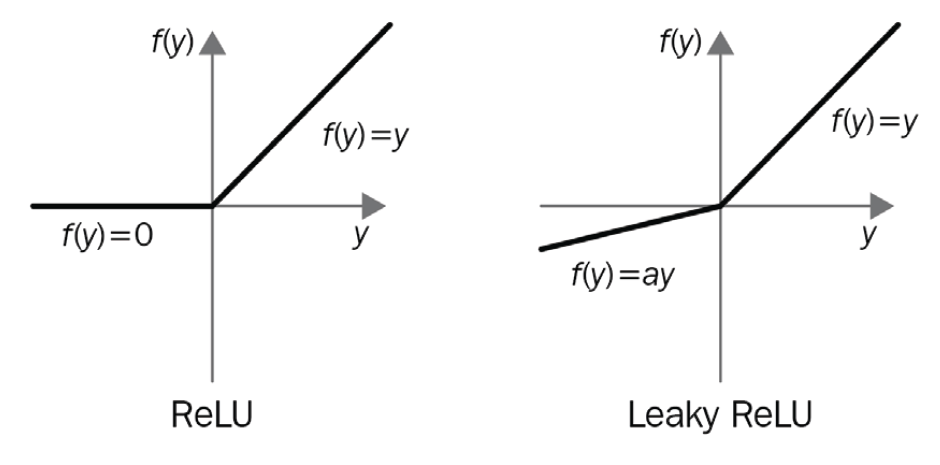

После применения $$ e_{ij} = LeakyReLU(a_{ij})$$
полученные значения не нормализованы!




## Softmax normalization

Для сравнения различных коэф. внимания, эти коэффициенты должны быть нормализованы. Для этого традиционно используется функция softmax:

$$ \alpha_{ij} = softmax_j(e_{ij}) = \cfrac{\exp(e_{ij})}{\sum_{k \in N[i] \exp(e_{ik})}},$$

где $N[i] = N(i) \cup \{i\}$ - соседи узла $i$ и сам узел $i$.

## Multi-head attention

* Расчет нескольких наборов эмбеддингов со своими коэф. внимания
* Повторим 3 предыдущих шага несколько раз $h_i^{k}$, где $k$ - номер набор (attention head).
* Далее, или осреднение (averaging) по полученным наборам

$$ h_i = \cfrac{1}{n} \sum\limits_{k = 1}^n h_i^k =\frac{1}{n} \sum\limits_{k = 1}^n \sum\limits_{j \in N[i]} \alpha_{ij}^k W^k x_j;$$

или конкатенация (concatenation):

$$ h_i =  \vert\vert_{k = 1}^n h_i^k =\vert\vert_{k = 1}^n \sum\limits_{j \in N[i]} \alpha_{ij}^k W^k x_j.$$



*   Конкатенация - если GAT это скрытый слой нейронной сети;
*   Осреднение - если GAT последний слой нейронной сети.





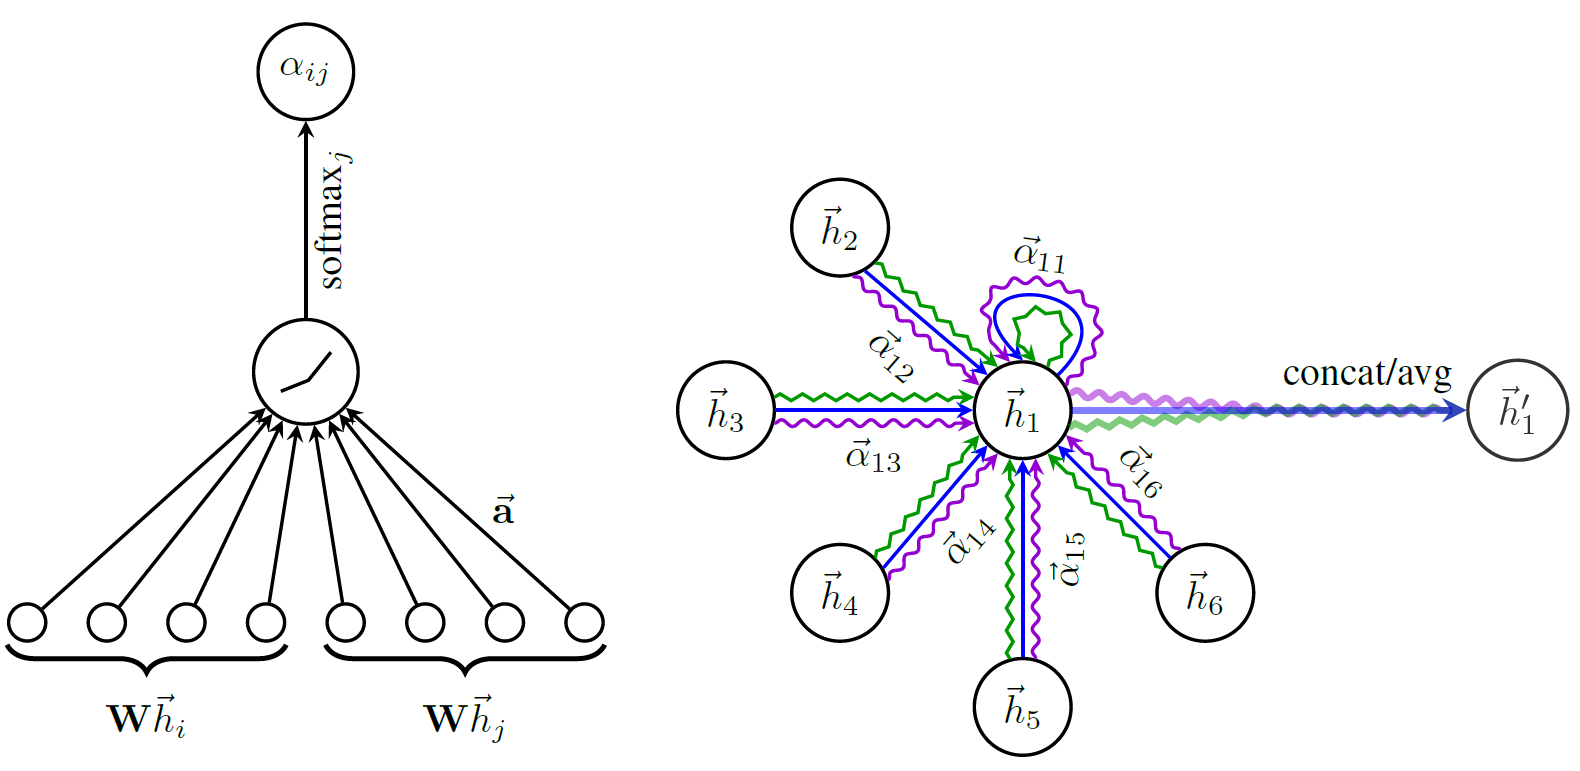

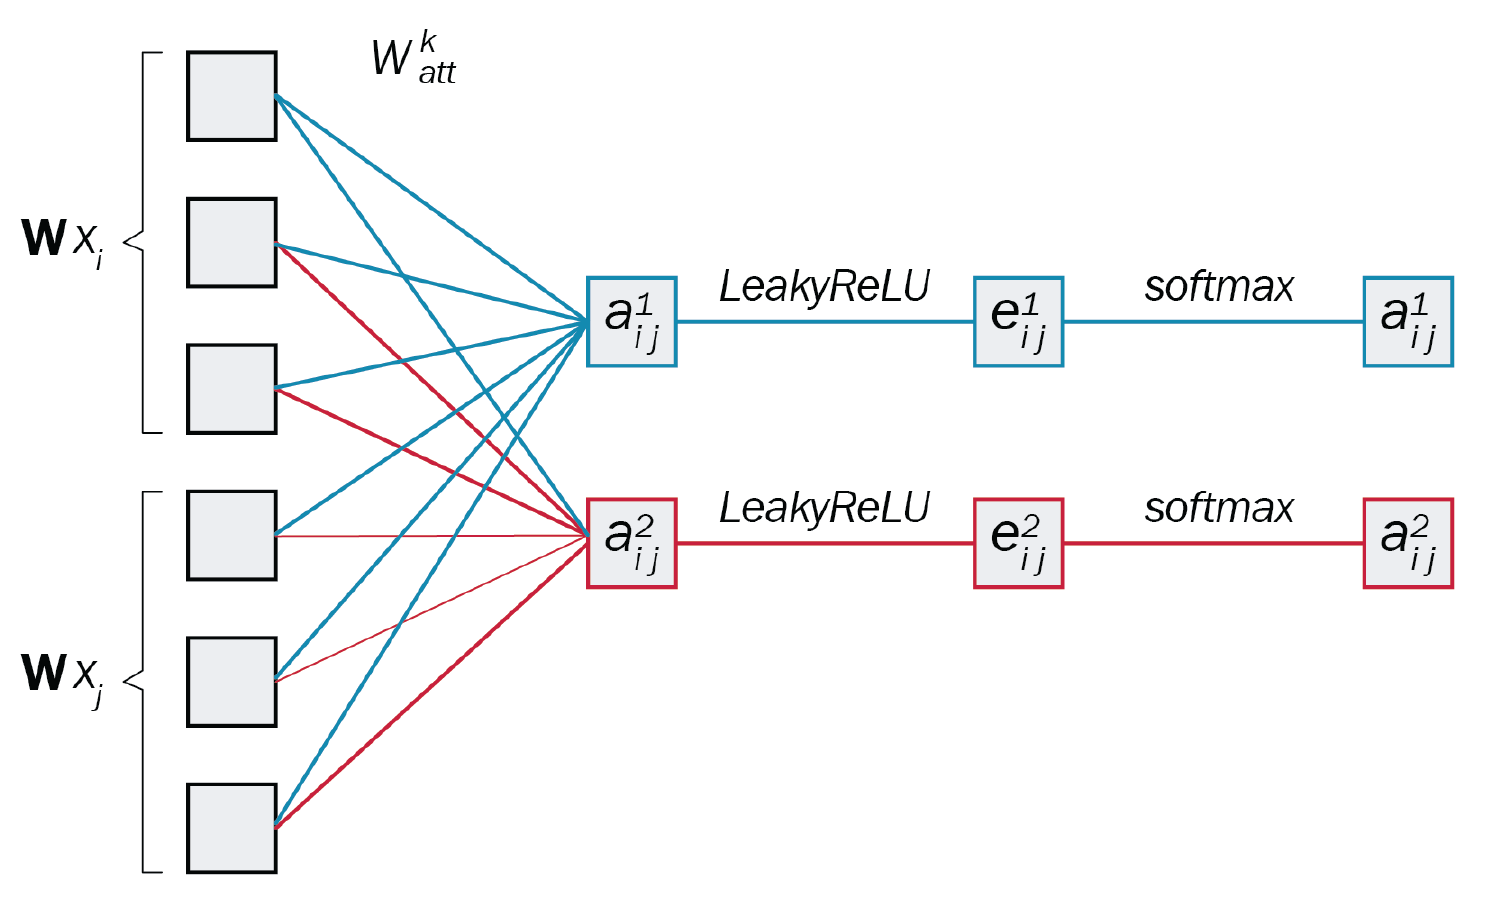

## **Graph Attention Operator**

* **GAT** ([Velickovic et al., 2017](https://arxiv.org/abs/1710.10903))

$$ \alpha_{ij} = \cfrac{\exp(LeakyReLU(W_{att}^T [W x_i\vert\vert W x_j]))}{\sum_{k \in N[i]} \exp(LeakyReLU(W_{att}^T [W x_i\vert\vert W x_k]))}$$

* **GATv2** ([Brody et al., 2021](https://arxiv.org/abs/2105.14491))

$$ \alpha_{ij} = \cfrac{\exp(W_{att}^T LeakyReLU(W[x_i\vert\vert x_j]))}{\sum_{k \in N[i]} \exp(W_{att}^T LeakyReLU(W[x_i\vert\vert x_k])}$$


# GAT with NumPy

Запишем graph attention operator в терминах матриц.

$h_i = \sum_{i \in N[i]} \alpha_{ij} W x_j$ или

$H = \tilde{A} W_\alpha X W^T$, где $W_\alpha$ - матрица коэфициентов внимания.



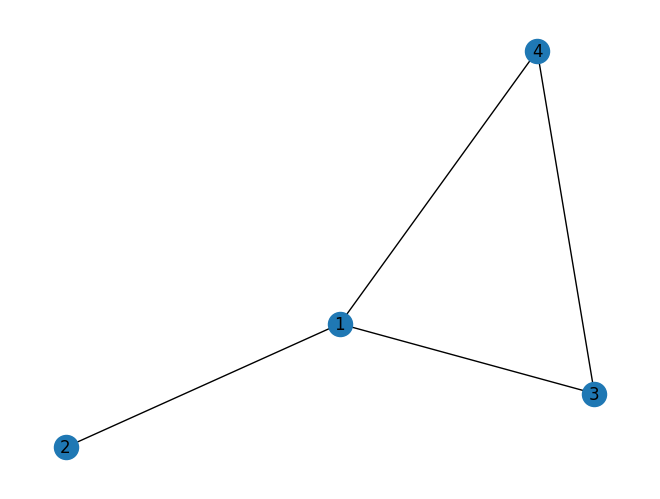

In [ ]:
# Граф
G = nx.Graph()
G.add_edges_from([(1, 2), (1, 3), (1, 4), (3, 4)])
nx.draw(G, with_labels = True)

In [ ]:
# Матрица смежности
A = nx.adjacency_matrix(G).toarray()

# Диагональная матрица степеней
G_node_degrees = [degree[1] for degree in G.degree()]
D = np.diag(G_node_degrees)

# Матрица смежности с учетом петель
A_tilde = A + np.identity(4)
D_tilde = D + np.identity(4)

In [ ]:
# Матрица начальных признаков
X = np.random.uniform(-1, 1, (4, 4))
X

array([[-0.15150119,  0.76233553, -0.72646259,  0.3423284 ],
       [-0.9516842 , -0.34008808,  0.38732595,  0.44781427],
       [ 0.5329578 , -0.40986256, -0.05155653, -0.97806522],
       [-0.25633834,  0.25161041, -0.15771995, -0.83384902]])

В GAT две матрицы весов: $W$ (обычная) и матрица весов внимания $W_\alpha$.

$W$ имеет размерность $\text{nb of hidden dims} \times \text{nb of nodes}$. В нашем примере $\text{nb of nodes} = 4$, пусть  $\text{nb of hidden dim} = 2$.

In [ ]:
W = np.random.uniform(-1, 1, (2, 4))
W

array([[ 0.09514831, -0.15186378, -0.90326597,  0.82198258],
       [-0.34951085,  0.69400056,  0.37948123,  0.32332048]])

Матрица внимания  $W_\alpha$ должна быть размера $1 \times 2\cdot dim\_h$:

In [ ]:
W_att = np.random.uniform(-1, 1, (1, 4))
W_att

array([[-0.82796997, -0.6422372 ,  0.17638707, -0.99033429]])

Конкатенация скрытых представлений для узлов $i$ и $j$.
Представим матрицу $\tilde{A}$ в координатном формате (COO format):
строки - вершина-начало ребра, столбцы - вершина-конец ребра.

In [ ]:
print(A_tilde)

[[1. 1. 1. 1.]
 [1. 1. 0. 0.]
 [1. 0. 1. 1.]
 [1. 0. 1. 1.]]


In [ ]:
# позиции ненулевых элементов
connections = np.where(A_tilde > 0)
connections

(array([0, 0, 0, 0, 1, 1, 2, 2, 2, 3, 3, 3]),
 array([0, 1, 2, 3, 0, 1, 0, 2, 3, 0, 2, 3]))

In [ ]:
# новые признаки
print(X @ W.T)

[[ 0.80739069  0.41701546]
 [-0.02066691  0.38837309]
 [-0.64443    -0.80651263]
 [-0.60554697 -0.06524143]]


In [ ]:
# Конкатенация
np.concatenate([(X @ W.T)[connections[0]], (X @ W.T)[connections[1]]], axis=1)

array([[ 0.80739069,  0.41701546,  0.80739069,  0.41701546],
       [ 0.80739069,  0.41701546, -0.02066691,  0.38837309],
       [ 0.80739069,  0.41701546, -0.64443   , -0.80651263],
       [ 0.80739069,  0.41701546, -0.60554697, -0.06524143],
       [-0.02066691,  0.38837309,  0.80739069,  0.41701546],
       [-0.02066691,  0.38837309, -0.02066691,  0.38837309],
       [-0.64443   , -0.80651263,  0.80739069,  0.41701546],
       [-0.64443   , -0.80651263, -0.64443   , -0.80651263],
       [-0.64443   , -0.80651263, -0.60554697, -0.06524143],
       [-0.60554697, -0.06524143,  0.80739069,  0.41701546],
       [-0.60554697, -0.06524143, -0.64443   , -0.80651263],
       [-0.60554697, -0.06524143, -0.60554697, -0.06524143]])

Далее, надо примененить линейное преобразование с матрицей $W_{att}$:

In [ ]:
a = W_att @ np.concatenate([(X @ W.T)[connections[0]], (X @ W.T)[connections[1]]], axis=1).T
a

array([[-1.20688952, -1.32458265, -0.25127009, -0.97851791, -0.5028875 ,
        -0.62058063,  0.78096966,  1.73658909,  1.00934127,  0.27270375,
         1.22832317,  0.50107535]])

Затем применим LeakyReLU.

In [ ]:
# LeakyReLU
def leaky_relu(x, alpha = 0.2):
    return np.maximum(alpha*x, x)

In [ ]:
e = leaky_relu(a)
e

array([[-0.2413779 , -0.26491653, -0.05025402, -0.19570358, -0.1005775 ,
        -0.12411613,  0.78096966,  1.73658909,  1.00934127,  0.27270375,
         1.22832317,  0.50107535]])

Эти значения надо правильно расставить в матрице $\text{nb of nodes} \times \text{nb of nodes}$:

In [ ]:
E = np.zeros(A.shape)
E[connections[0], connections[1]] = e[0]

E

array([[-0.2413779 , -0.26491653, -0.05025402, -0.19570358],
       [-0.1005775 , -0.12411613,  0.        ,  0.        ],
       [ 0.78096966,  0.        ,  1.73658909,  1.00934127],
       [ 0.27270375,  0.        ,  1.22832317,  0.50107535]])

Следующий шаг - нормализация коэф. внимания с помощью softmax.

In [ ]:
# softmax

def softmax2D(x, axis):
    e = np.exp(x - np.expand_dims(np.max(x, axis = axis), axis))
    sum = np.expand_dims(np.sum(e, axis = axis), axis)
    return e/ sum

In [ ]:
np.exp(E - np.expand_dims(np.max(E, axis = 1), 1))

array([[0.82603025, 0.80681368, 1.        , 0.8646335 ],
       [0.90431503, 0.88327726, 1.        , 1.        ],
       [0.38457385, 0.17612011, 1.        , 0.48323712],
       [0.38457385, 0.29278311, 1.        , 0.48323712]])

Матрица $W_\alpha$ содержит веса взаимного влияния для всех ребер исходного графа.

In [ ]:
W_alpha = softmax2D(E, 1)
W_alpha

array([[0.23617886, 0.23068446, 0.28592036, 0.24721632],
       [0.23875723, 0.23320284, 0.26401997, 0.26401997],
       [0.18815402, 0.08616734, 0.48925329, 0.23642535],
       [0.1779945 , 0.13551047, 0.46283567, 0.22365937]])

Финальные "эмбединги"

In [ ]:
H = A_tilde.T @ W_alpha @ X @ W.T
H

array([[-0.89121786, -0.65777564],
       [-0.29010377, -0.09867057],
       [-0.74914975, -0.61775032],
       [-0.74914975, -0.61775032]])

# GAT в PyTorch Geometric

Классификация узлов в датасете Cora  (по статье [Velickovic et al, 2017](https://arxiv.org/abs/1710.10903)).

In [ ]:
# dataset Cora
from torch_geometric.datasets import Planetoid

dataset = Planetoid(root=".", name="Cora")
data = dataset[0]
data

Processing...
Done!


Data(x=[2708, 1433], edge_index=[2, 10556], y=[2708], train_mask=[2708], val_mask=[2708], test_mask=[2708])

In [ ]:
import matplotlib.pyplot as plt
import torch.nn.functional as F
from torch_geometric.nn import GATv2Conv
from torch.nn import Linear, Dropout
from torch_geometric.utils import degree

Метрика accuracy доля правильных ответов алгоритма:

$ACCURACY = \cfrac{TP + TN}{TP+TN+FP+FN}$.

In [15]:
def accuracy(y_pred, y_true):
    """Calculate accuracy."""
    return torch.sum(y_pred == y_true) / len(y_true)

2 слоя

*   2 GAT слоя: $8$ heads для первого слоя

*   2 dropout слоя, чтобы избежать переобучения (выключение нейронов с некоторой вероятностью)
*   Функция активации Exponential Linear Unit (ELU) вместо LeaakyReLU



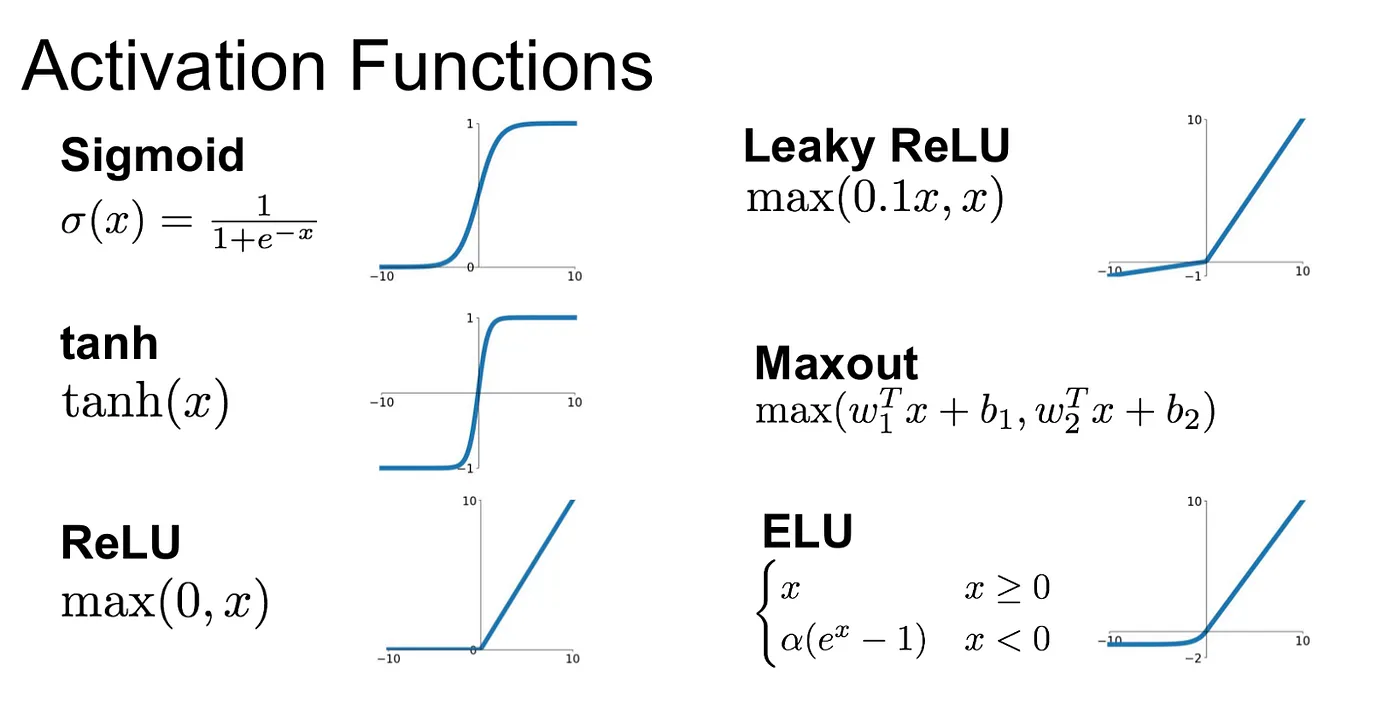

In [16]:
class GAT(torch.nn.Module):
    def __init__(self, dim_in, dim_h, dim_out, heads=8):
        super().__init__()
        self.gat1 = GATv2Conv(dim_in, dim_h, heads=heads)
        self.gat2 = GATv2Conv(dim_h*heads, dim_out, heads=1)

    def forward(self, x, edge_index):
        h = F.dropout(x, p=0.6, training=self.training)
        h = self.gat1(h, edge_index)
        h = F.elu(h)
        h = F.dropout(h, p=0.6, training=self.training)
        h = self.gat2(h, edge_index)
        return F.log_softmax(h, dim=1)

    def fit(self, data, epochs):
        criterion = torch.nn.CrossEntropyLoss()
        optimizer = torch.optim.Adam(self.parameters(), lr=0.01, weight_decay=0.01)

        self.train()
        for epoch in range(epochs+1):
            optimizer.zero_grad()
            out = self(data.x, data.edge_index)
            loss = criterion(out[data.train_mask], data.y[data.train_mask])
            acc = accuracy(out[data.train_mask].argmax(dim=1), data.y[data.train_mask])
            loss.backward()
            optimizer.step()

            if(epoch % 20 == 0):
                val_loss = criterion(out[data.val_mask], data.y[data.val_mask])
                val_acc = accuracy(out[data.val_mask].argmax(dim=1), data.y[data.val_mask])
                print(f'Epoch {epoch:>3} | Train Loss: {loss:.3f} | Train Acc: {acc*100:>5.2f}% | Val Loss: {val_loss:.2f} | Val Acc: {val_acc*100:.2f}%')

    @torch.no_grad()
    def test(self, data):
        self.eval()
        out = self(data.x, data.edge_index)
        acc = accuracy(out.argmax(dim=1)[data.test_mask], data.y[data.test_mask])
        return acc


In [ ]:
# Создание GAT модели
gat = GAT(dataset.num_features, 32, dataset.num_classes)
print(gat)

# Обучение
gat.fit(data, epochs=100)

# Тестирование
acc = gat.test(data)
print(f'GAT test accuracy: {acc*100:.2f}%')

GAT(
  (gat1): GATv2Conv(1433, 32, heads=8)
  (gat2): GATv2Conv(256, 7, heads=1)
)
Epoch   0 | Train Loss: 1.949 | Train Acc: 17.86% | Val Loss: 1.92 | Val Acc: 17.20%
Epoch  20 | Train Loss: 0.231 | Train Acc: 98.57% | Val Loss: 0.93 | Val Acc: 74.00%
Epoch  40 | Train Loss: 0.153 | Train Acc: 100.00% | Val Loss: 0.81 | Val Acc: 76.40%
Epoch  60 | Train Loss: 0.238 | Train Acc: 96.43% | Val Loss: 0.79 | Val Acc: 76.60%
Epoch  80 | Train Loss: 0.175 | Train Acc: 97.14% | Val Loss: 0.93 | Val Acc: 71.20%
Epoch 100 | Train Loss: 0.165 | Train Acc: 100.00% | Val Loss: 0.89 | Val Acc: 73.40%
GAT test accuracy: 79.90%


# Задание

1. Выполните классификацию узлов датасета CiteSeer (также из Platenoid) по 6 категориям с помощью нейронной сети, состоящей из 2х GAT слоев. Размерность скрытого представления - 16.
2. Чему равна доля правильно классифицированных узлов?
3. Чему равна доля правильно классифицированных узлов степени 1, 2, 3, 4, 5 и степени 6 и выше?
4. Сравните долю правильно классифицированных узлов в сети Cora в зависимости от степени узла.

In [4]:
class GAT(torch.nn.Module):
    def __init__(self, dim_in, dim_h, dim_out, heads=8):
        super().__init__()
        self.gat1 = GATv2Conv(dim_in, dim_h, heads=heads)
        self.gat2 = GATv2Conv(dim_h*heads, dim_out, heads=1)

    def forward(self, x, edge_index):
        h = F.dropout(x, p=0.6, training=self.training)
        h = self.gat1(h, edge_index)
        h = F.elu(h)
        h = F.dropout(h, p=0.6, training=self.training)
        h = self.gat2(h, edge_index)
        return F.log_softmax(h, dim=1)

    def fit(self, data, epochs):
        criterion = torch.nn.CrossEntropyLoss()
        optimizer = torch.optim.Adam(self.parameters(), lr=0.01, weight_decay=0.01)

        self.train()
        for epoch in range(epochs+1):
            optimizer.zero_grad()
            out = self(data.x, data.edge_index)
            loss = criterion(out[data.train_mask], data.y[data.train_mask])
            acc = accuracy(out[data.train_mask].argmax(dim=1), data.y[data.train_mask])
            loss.backward()
            optimizer.step()

            if(epoch % 20 == 0):
                val_loss = criterion(out[data.val_mask], data.y[data.val_mask])
                val_acc = accuracy(out[data.val_mask].argmax(dim=1), data.y[data.val_mask])
                print(f'Epoch {epoch:>3} | Train Loss: {loss:.3f} | Train Acc: {acc*100:>5.2f}% | Val Loss: {val_loss:.2f} | Val Acc: {val_acc*100:.2f}%')

    # @torch.no_grad()
    # def test(self, data):
    #     self.eval()
    #     out = self(data.x, data.edge_index)
    #     acc = accuracy(out.argmax(dim=1)[data.test_mask], data.y[data.test_mask])
    #     return acc

    @torch.no_grad()
    def test(self, data):
        self.eval()
        out = self(data.x, data.edge_index)
        pred = out.argmax(dim=1)[data.test_mask]
        true = data.y[data.test_mask]
        acc = accuracy(pred, true)
        return acc, pred, true

In [5]:
def accuracy(y_pred, y_true):
    """Calculate accuracy."""
    return torch.sum(y_pred == y_true) / len(y_true)

In [6]:
# from torch_geometric.utils import degree
from torch_geometric.datasets import Planetoid

In [7]:
dataset_citeseer = Planetoid(root=".", name="CiteSeer")
data_citeseer = dataset_citeseer[0]

dataset_cora = Planetoid(root=".", name="Cora")
data_cora = dataset_cora[0]

In [8]:
def accuracy_by_degree(pred, true, degrees, test_mask):
    results = {}
    test_degrees = degrees[test_mask]

    for degree in range(1, 6):
        mask = torch.eq(test_degrees, degree)
        if mask.sum() > 0:
            results[degree] = accuracy(pred[mask], true[mask])
        else:
            results[degree] = None

    mask = torch.ge(test_degrees, 6)
    if mask.sum() > 0:
        results["6+"] = accuracy(pred[mask], true[mask])
    else:
        results["6+"] = None

    return results

In [9]:
gat_citeseer = GAT(dataset_citeseer.num_features, 16, dataset_citeseer.num_classes, heads=8)
gat_citeseer.fit(data_citeseer, epochs=200)
acc_citeseer, pred_citeseer, true_citeseer = gat_citeseer.test(data_citeseer)
print(f"\n CiteSeer Test Accuracy: {acc_citeseer*100:.2f}%")

degrees_citeseer = degree(data_citeseer.edge_index[0])
acc_by_deg_citeseer = accuracy_by_degree(pred_citeseer, true_citeseer, degrees_citeseer, data_citeseer.test_mask)
print("Accuracy by degree for CiteSeer:", acc_by_deg_citeseer)

Epoch   0 | Train Loss: 1.785 | Train Acc: 20.83% | Val Loss: 1.79 | Val Acc: 18.60%
Epoch  20 | Train Loss: 0.149 | Train Acc: 98.33% | Val Loss: 1.22 | Val Acc: 60.40%
Epoch  40 | Train Loss: 0.158 | Train Acc: 98.33% | Val Loss: 1.17 | Val Acc: 58.20%
Epoch  60 | Train Loss: 0.119 | Train Acc: 100.00% | Val Loss: 1.14 | Val Acc: 59.40%
Epoch  80 | Train Loss: 0.137 | Train Acc: 99.17% | Val Loss: 1.12 | Val Acc: 61.40%
Epoch 100 | Train Loss: 0.136 | Train Acc: 97.50% | Val Loss: 1.20 | Val Acc: 61.00%
Epoch 120 | Train Loss: 0.094 | Train Acc: 100.00% | Val Loss: 1.22 | Val Acc: 56.40%
Epoch 140 | Train Loss: 0.107 | Train Acc: 100.00% | Val Loss: 1.17 | Val Acc: 62.20%
Epoch 160 | Train Loss: 0.098 | Train Acc: 99.17% | Val Loss: 1.16 | Val Acc: 64.20%
Epoch 180 | Train Loss: 0.097 | Train Acc: 99.17% | Val Loss: 1.14 | Val Acc: 64.20%
Epoch 200 | Train Loss: 0.093 | Train Acc: 100.00% | Val Loss: 1.16 | Val Acc: 62.60%

 CiteSeer Test Accuracy: 70.90%
Accuracy by degree (CiteSeer

In [10]:
gat_cora = GAT(dataset_cora.num_features, 16, dataset_cora.num_classes, heads=8)
gat_cora.fit(data_cora, epochs=200)
acc_cora, pred_cora, true_cora = gat_cora.test(data_cora)
print(f"\nCora Test Accuracy: {acc_cora*100:.2f}%")

degrees_cora = degree(data_cora.edge_index[0])
acc_by_deg_cora = accuracy_by_degree(pred_cora, true_cora, degrees_cora, data_cora.test_mask)
print("Accuracy by degree for Cora:", acc_by_deg_cora)

Epoch   0 | Train Loss: 1.952 | Train Acc: 18.57% | Val Loss: 1.96 | Val Acc: 14.40%
Epoch  20 | Train Loss: 0.163 | Train Acc: 100.00% | Val Loss: 0.90 | Val Acc: 71.20%
Epoch  40 | Train Loss: 0.160 | Train Acc: 97.86% | Val Loss: 0.80 | Val Acc: 77.20%
Epoch  60 | Train Loss: 0.144 | Train Acc: 100.00% | Val Loss: 0.93 | Val Acc: 70.80%
Epoch  80 | Train Loss: 0.157 | Train Acc: 97.14% | Val Loss: 0.98 | Val Acc: 71.20%
Epoch 100 | Train Loss: 0.133 | Train Acc: 100.00% | Val Loss: 0.91 | Val Acc: 73.60%
Epoch 120 | Train Loss: 0.161 | Train Acc: 98.57% | Val Loss: 1.00 | Val Acc: 72.00%
Epoch 140 | Train Loss: 0.139 | Train Acc: 98.57% | Val Loss: 0.92 | Val Acc: 75.20%
Epoch 160 | Train Loss: 0.193 | Train Acc: 95.71% | Val Loss: 1.00 | Val Acc: 71.00%
Epoch 180 | Train Loss: 0.186 | Train Acc: 97.14% | Val Loss: 0.99 | Val Acc: 71.80%
Epoch 200 | Train Loss: 0.168 | Train Acc: 96.43% | Val Loss: 1.05 | Val Acc: 73.00%

Cora Test Accuracy: 81.60%
Accuracy by degree (Cora): {1: ten

В обеих сетях узлы с низкой степенью классифицируются хуже, так как у них мало соседей и меньше информации для агрегации.

Модель GAT лучше справляется с классификацией узлов в Cora, особенно у узлов с высокой степенью. В CiteSeer узлы со степенью 5 дают наилучший результат.